<h1><center>Parameter-Efficient Fine-tuning</center></h1>

<text>Прям вообще топ</text>

<h2>Загрузка датасета</h2>

In [1]:
import torch
from torch import nn
import subprocess
import os


os.environ['TOKENIZERS_PARALLELISM'] = 'false'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
# !pip install datasets

In [2]:
from datasets import load_dataset


train_dataset = load_dataset('nyu-mll/glue', 'sst2', split='train[:50000]')
valid_dataset = load_dataset('nyu-mll/glue', 'sst2', split='validation')

In [3]:
train_dataset[0]

{'sentence': 'hide new secretions from the parental units ',
 'label': 0,
 'idx': 0}

In [4]:
train_dataset[2]

{'sentence': 'that loves its characters and communicates something rather beautiful about human nature ',
 'label': 1,
 'idx': 2}

In [5]:
len(train_dataset), len(valid_dataset)

(50000, 872)

<h2>Инициализация токенизатора и модели</h2>

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification


model_checkpoint = 'gpt2'

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
tokenizer.add_special_tokens({'pad_token': '[PAD]'})

1

In [7]:
class Model(nn.Module):
    def __init__(self, tokenizer, num_classes):
        super().__init__()
        self.model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint,
                                                                        num_labels=num_classes)
        self.model.resize_token_embeddings(len(tokenizer))
        self.config = self.model.config

    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None,
                *args, **kwards):
        out = self.model.transformer(
            input_ids=input_ids, inputs_embeds=inputs_embeds,
            attention_mask=attention_mask
        ).last_hidden_state
        lens = attention_mask.sum(-1).cpu() - 1
        out = out[torch.arange(len(lens)), lens.to(torch.long)]
        return self.model.score(out)

    @property
    def device(self):
        return next(self.model.parameters()).device
    

num_classes = 2
model = Model(tokenizer, num_classes)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


In [8]:
model

Model(
  (model): GPT2ForSequenceClassification(
    (transformer): GPT2Model(
      (wte): Embedding(50258, 768)
      (wpe): Embedding(1024, 768)
      (drop): Dropout(p=0.1, inplace=False)
      (h): ModuleList(
        (0-11): 12 x GPT2Block(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): GPT2Attention(
            (c_attn): Conv1D(nf=2304, nx=768)
            (c_proj): Conv1D(nf=768, nx=768)
            (attn_dropout): Dropout(p=0.1, inplace=False)
            (resid_dropout): Dropout(p=0.1, inplace=False)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): GPT2MLP(
            (c_fc): Conv1D(nf=3072, nx=768)
            (c_proj): Conv1D(nf=768, nx=3072)
            (act): NewGELUActivation()
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
      )
      (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (score)

In [9]:
print('Num parameters: ', sum(p.numel() for p in model.parameters()))

Num parameters:  124442112


In [10]:
model.device


device(type='cpu')

<h2>Проверка токенизатора

In [11]:
tokenizer(train_dataset[0]['sentence'])

{'input_ids': [24717, 649, 3200, 507, 422, 262, 21694, 4991, 220], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [12]:
from torch.utils.data import DataLoader


batch_size = 32

train_loader = DataLoader(train_dataset, shuffle=True, batch_size=batch_size)
valid_loader = DataLoader(valid_dataset, shuffle=False, batch_size=batch_size)

In [13]:
import numpy as np


print('         0     1')
classes = [t['label'] for t in train_dataset]
print(f'Train: {1 - np.mean(classes):0.3f} {np.mean(classes):0.3f}')

classes = [t['label'] for t in valid_dataset]
print(f'Valid: {1 - np.mean(classes):0.3f} {np.mean(classes):0.3f}')

         0     1
Train: 0.442 0.558
Valid: 0.491 0.509


<h2>Обновление функции для обучения моделей

In [14]:
from IPython.display import clear_output
from random import sample
from tqdm import tqdm
import matplotlib.pyplot as plt
from torchmetrics.functional import accuracy
from torch.optim import AdamW
import seaborn as sns


sns.set_theme()

In [15]:
def training_loop_fn(model, opt, total_num_iters, eval_freq,
                     train_loader, valid_loader, accumulate_step=4):
    history = {'train_loss': [], 'train_acc': [],
               'valid_loss': [], 'valid_acc': []}
    
    global_step = 0

    criterion = nn.CrossEntropyLoss()
    model.train()
    while True:
        for batch in tqdm(train_loader):
            tokenized = tokenizer(batch['sentence'], padding=True, return_tensors='pt')
            for k, v in tokenized.items():
                tokenized[k] = v.to(device)

            with torch.autocast(device_type='cuda', dtype=torch.float16):
                logits = model(tokenized['input_ids'], tokenized['attention_mask'],
                return_dict=False)
            targets = batch['label'].to(device)
            loss = criterion(logits, targets)

            loss.backward()
            if (global_step + 1) % accumulate_step == 0:
                opt.step()
                opt.zero_grad()

            preds = nn.functional.softmax(logits, dim=-1)[:, 1]
            acc = accuracy(preds, targets, 'binary')

            history['train_loss'].append((global_step, loss.item()))
            history['train_acc'].append((global_step, acc.item()))

            if global_step % eval_freq == 0:
                val_loss, val_acc = evaluate(model, valid_loader)
                history['valid_loss'].append((global_step, val_loss))
                history['valid_acc'].append((global_step, val_acc))
                model.train()

            if global_step % 250 == 0:
                clear_output(wait=True)

                plt.figure(figsize=(15, 5))

                plt.subplot(121)
                plt.plot(*zip(*history['train_loss']), alpha=.5, label='train_loss')
                if len(history['valid_loss']):
                    plt.plot(*zip(*history['valid_loss']), color='red', label='valid_loss')
                
                plt.subplot(122)
                plt.plot(*zip(*history['train_acc']), alpha=.5, label='train_acc')
                if len(history['valid_loss']):
                    plt.plot(*zip(*history['valid_acc']), color='red', label='valid_acc')
                plt.legend()
                plt.show()
            
            global_step += 1
            if global_step > total_num_iters:
                break
        else:
            continue
        break

@torch.inference_mode()
def evaluate(model, dataloader):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    loss_epoch = .0
    num_epoch = 0
    preds_list = []
    targets_list = []

    for valid_batch in dataloader:
        tokenized = tokenizer(valid_batch['sentence'], padding=True, return_tensors='pt')
        for k, v in tokenized.items():
            tokenized[k] = v.to(device)

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits = model(tokenized['input_ids'], tokenized['attention_mask'],
            return_dict=False)

        loss = criterion(logits, valid_batch['label'].to(device))
        num = logits.shape[0]

        loss_epoch += loss.item() * num
        num_epoch += num
        preds = nn.functional.softmax(logits, dim=-1)[:, 1]

        targets_list += valid_batch['label'].tolist()
        preds_list += preds.tolist()

    acc = accuracy(torch.tensor(preds_list).to(device),
                   torch.tensor(targets_list).to(device), 'binary')
    return loss_epoch / num_epoch, acc.item()

<h2>Fine-tuning

In [17]:
optimizer = AdamW(model.parameters(), lr=2e-6)
model.to(device)

Model(
  (model): GPT2ForSequenceClassification(
    (transformer): GPT2Model(
      (wte): Embedding(50258, 768)
      (wpe): Embedding(1024, 768)
      (drop): Dropout(p=0.1, inplace=False)
      (h): ModuleList(
        (0-11): 12 x GPT2Block(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): GPT2Attention(
            (c_attn): Conv1D(nf=2304, nx=768)
            (c_proj): Conv1D(nf=768, nx=768)
            (attn_dropout): Dropout(p=0.1, inplace=False)
            (resid_dropout): Dropout(p=0.1, inplace=False)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): GPT2MLP(
            (c_fc): Conv1D(nf=3072, nx=768)
            (c_proj): Conv1D(nf=768, nx=3072)
            (act): NewGELUActivation()
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
      )
      (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (score)

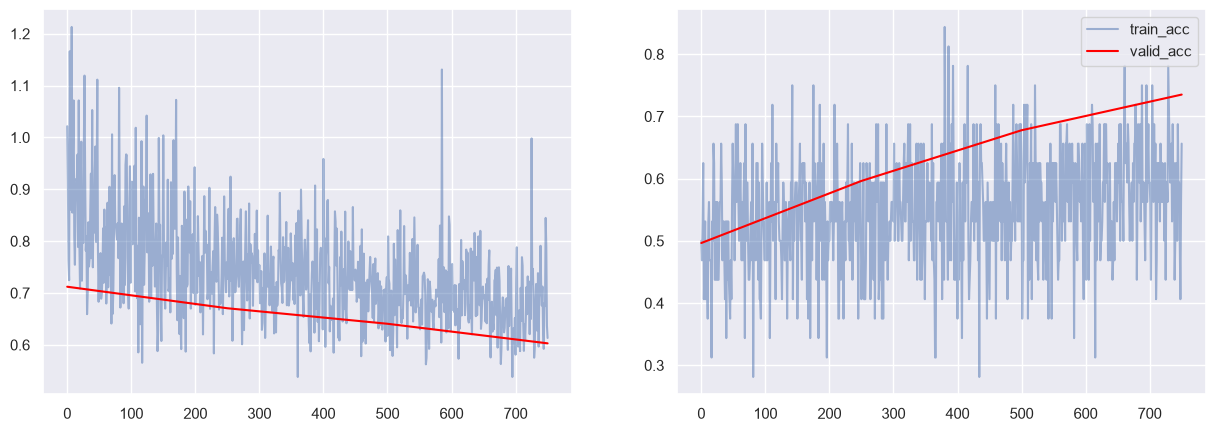

 48%|████▊     | 750/1563 [02:25<02:37,  5.17it/s]


In [18]:
training_loop_fn(model, optimizer, 750, 250, train_loader, valid_loader)

In [19]:
val_loss, val_acc = evaluate(model, valid_loader)
print(f'VAl_LOSS: {val_loss}')
print(f'VAl_ACC: {val_acc}')

VAl_LOSS: 0.6029198322821101
VAl_ACC: 0.7350917458534241


In [ ]:
torch.save(model, 'gpt2_step1.pt')

<h2>Linear Probing

In [ ]:
import gc


def clear_cuda(model, optimizer):
    if 'model' in locals():
        del model
    if 'optimizer' in locals():
        del optimizer

    gc.collect()

    torch.cuda.empty_cache()

if 'model' in locals():
    del model
if 'optimizer' in locals():
    del optimizer

gc.collect()

torch.cuda.empty_cache()

NameError: name 'optimizer' is not defined

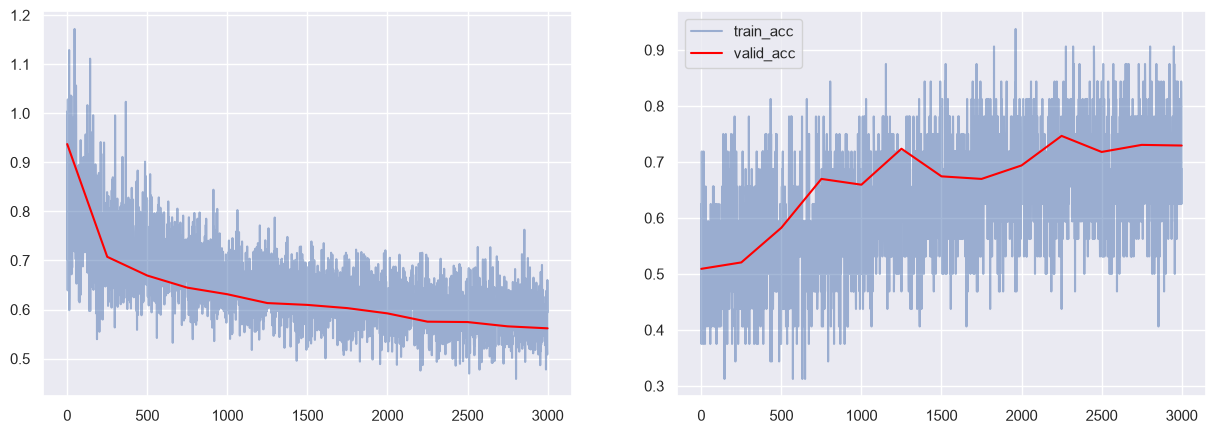

 92%|█████████▏| 1437/1563 [04:02<00:21,  5.93it/s]


In [23]:
model = Model(tokenizer, num_classes).to(device)
optimizer = AdamW(model.model.score.parameters(), lr=1e-4)

training_loop_fn(model, optimizer, 750 * 4, 250, train_loader, valid_loader)

In [24]:
val_loss, val_acc = evaluate(model, valid_loader)
print(f'VAl_LOSS: {val_loss}')
print(f'VAl_ACC: {val_acc}')

VAl_LOSS: 0.5617160622133027
VAl_ACC: 0.7293577790260315


In [25]:
torch.save(model.model.score.state_dict(),'head.pt')

In [28]:
clear_cuda(model, optimizer)

<h2>LoRA</h2>

(Low-Rank Adaptation) - это метод эффективной настройки (fine-tuning) больших нейросетей. Метод замораживает базовые веса модели и обучает лишь малую часть дополнительных матриц с низким рангом, что экономит память и время

Так-то в изначальной статье добавляем веса только к K, а мы будем ко всем (W, Q, K), так как в gpt2 они в одном слое и разграничивать труднее.

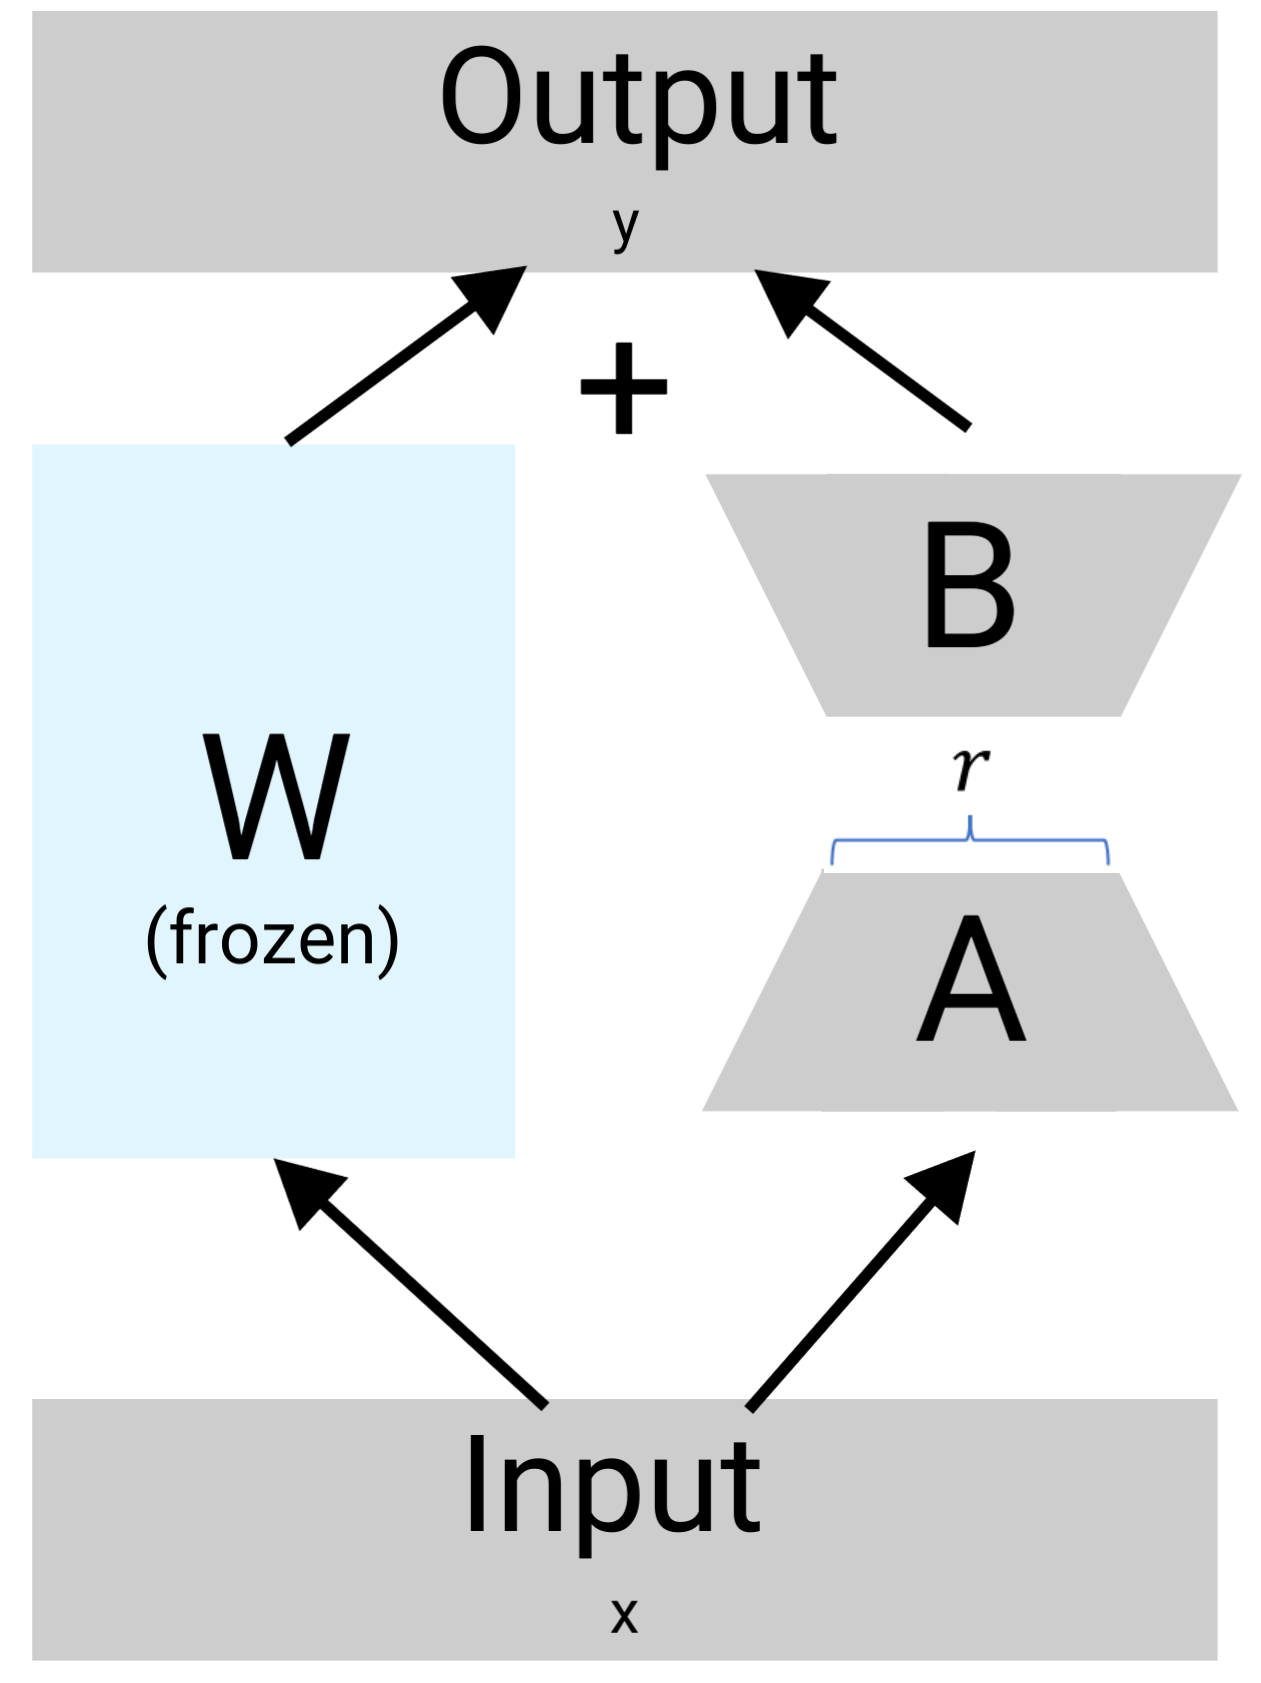

In [28]:
model

Model(
  (model): GPT2ForSequenceClassification(
    (transformer): GPT2Model(
      (wte): Embedding(50258, 768)
      (wpe): Embedding(1024, 768)
      (drop): Dropout(p=0.1, inplace=False)
      (h): ModuleList(
        (0-11): 12 x GPT2Block(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): GPT2Attention(
            (c_attn): Conv1D(nf=2304, nx=768)
            (c_proj): Conv1D(nf=768, nx=768)
            (attn_dropout): Dropout(p=0.1, inplace=False)
            (resid_dropout): Dropout(p=0.1, inplace=False)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): GPT2MLP(
            (c_fc): Conv1D(nf=3072, nx=768)
            (c_proj): Conv1D(nf=768, nx=3072)
            (act): NewGELUActivation()
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
      )
      (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (score)

In [ ]:
# !pip install peft

   ---------------------------------------- 0.0/775.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/775.8 kB ? eta -:--:--
   ---------------------------------------- 775.8/775.8 kB 5.5 MB/s  0:00:00


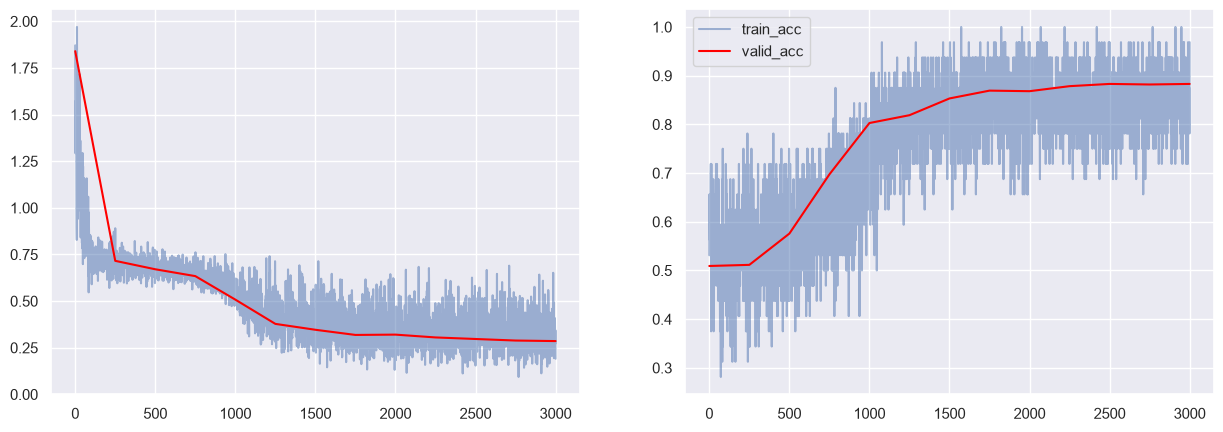

 92%|█████████▏| 1437/1563 [03:25<00:17,  7.00it/s]


In [58]:
from peft import get_peft_model, LoraConfig, TaskType


peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS, inference_mode=False, r=8,
    lora_dropout=.1, target_modules=['c_attn']
)

model = Model(tokenizer, num_classes).to(device)
lora_model = get_peft_model(model, peft_config).to(device)
lora_model.print_trainable_parameters()

optimizer = AdamW(lora_model.model.parameters(), lr=1e-4)
torch.cuda.empty_cache()

training_loop_fn(lora_model, optimizer, 750 * 4, 250, train_loader, valid_loader)

In [59]:
val_loss, val_acc = evaluate(lora_model, valid_loader)
print(f'VAl_LOSS: {val_loss}')
print(f'VAl_ACC: {val_acc}')

VAl_LOSS: 0.2857251648509174
VAl_ACC: 0.8830274939537048


In [60]:
torch.save(lora_model.base_model.model.model.score.state_dict(), 'lora_head.pt')

In [61]:
clear_cuda(lora_model, optimizer)

<h2>Prompt Tuning</h2>

— относиться экслюзивно не только к трансформерам, но и к декодерам. Т.е мы обучаем ещё и prompt (модель делает сама prompt)

In [77]:
from peft import PromptTuningConfig, PromptTuningInit


print(len(tokenizer('Predict if sentiment of this review is positive or negative')['input_ids']))

init = {PromptTuningInit.TEXT: 'Predict if sentiment of this review is positive or negative'}

config = model.config
pert_config = PromptTuningConfig(
    prompt_tuning_init = init,
    task_type = TaskType.SEQ_CLS,
    inference_mode = False,
    num_virtual_tokens = 12,
    num_layers = config.n_layer,
    token_dim = config.n_embd,
    num_attention_heads = config.n_head,
)

model = Model(tokenizer, num_classes).to(device)
pt_model = get_peft_model(model, pert_config).to(device)

pt_model.print_trainable_parameters()

11


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 10,752 || all params: 124,452,864 || trainable%: 0.0086


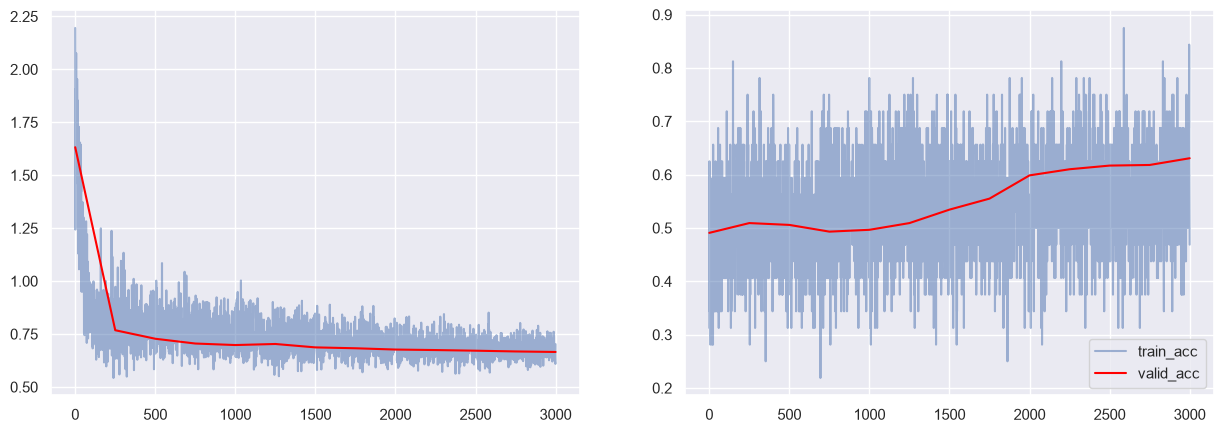

 92%|█████████▏| 1437/1563 [04:29<00:23,  5.33it/s]


In [78]:
optimizer = AdamW(pt_model.parameters(), lr=1e-4)

training_loop_fn(pt_model, optimizer, 750 * 4, 250, train_loader, valid_loader)

In [79]:
val_loss, val_acc = evaluate(pt_model, valid_loader)
print(f'VAl_LOSS: {val_loss}')
print(f'VAl_ACC: {val_acc}')

VAl_LOSS: 0.6652854429472477
VAl_ACC: 0.6307339668273926


In [81]:
torch.save(pt_model.state_dict(), 'prompt_head.pt')

In [82]:
del pt_model
del optimizer

torch.cuda.empty_cache()

<h2>LP-FT</h2>

— сначала дообучаем голову (Linear Probing), далее к новой такой же модели с загруженными весами добавляем эту голову, а далее дообучиваем всю модель (FineTuning)

In [16]:
chkpt = torch.load('head.pt')
chkpt.keys()

odict_keys(['weight'])

In [17]:
chkpt

OrderedDict([('weight',
              tensor([[ 0.0164, -0.0007,  0.0295,  ...,  0.0140, -0.0065,  0.0165],
                      [-0.0101,  0.0140, -0.0081,  ...,  0.0022,  0.0022, -0.0011]],
                     device='cuda:0'))])

In [18]:
model = Model(tokenizer, num_classes).to(device)
model.model.score.load_state_dict(chkpt)
optimizer = AdamW(model.parameters(), lr=2e-6)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


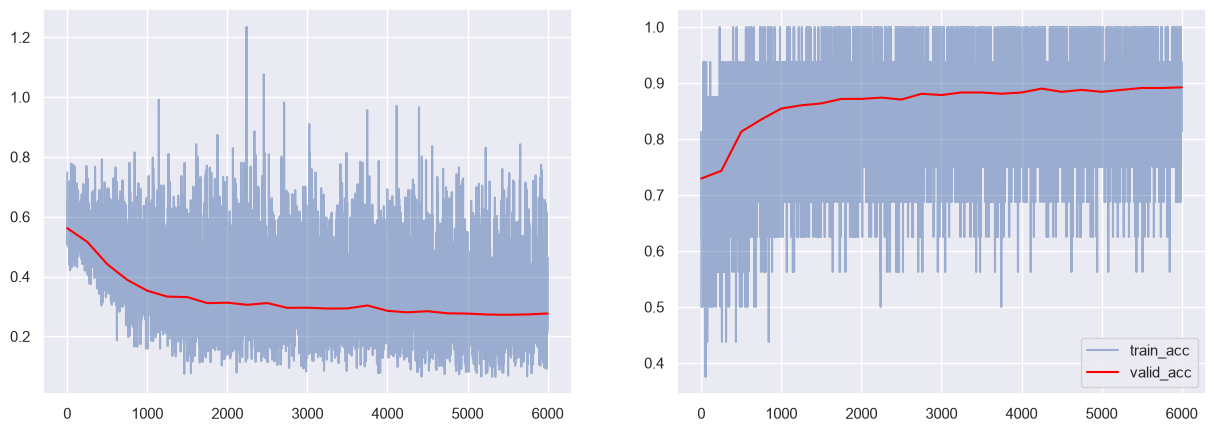

 92%|█████████▏| 2875/3125 [04:33<00:23, 10.51it/s]


In [19]:
batch_size = 16

train_loader = DataLoader(train_dataset, shuffle=True, batch_size=batch_size)
valid_loader = DataLoader(valid_dataset, shuffle=False, batch_size=batch_size)
training_loop_fn(model, optimizer, 750 * 8, 250, train_loader, valid_loader, accumulate_step=8)

In [20]:
val_loss, val_acc = evaluate(model, valid_loader)
print(f'VAl_LOSS: {val_loss}')
print(f'VAl_ACC: {val_acc}')

VAl_LOSS: 0.2763100720326835
VAl_ACC: 0.892201840877533


<h2>Тестирование модели

In [21]:
@torch.inference_mode()
def predict(text, target=0):
    tokenized = tokenizer(text, return_tensors='pt')
    for k, v in tokenized.items():
        tokenized[k] = v.to(device)
    
    logits = model(tokenized['input_ids'], tokenized['attention_mask'],
    return_dict=False)
    probs = torch.nn.functional.softmax(logits, dim=-1)
    predicted_class_id = int(torch.argmax(logits, dim=-1))

    print(f'text: {text}')
    print(f'target: {target}, pred: {predicted_class_id}')
    print(f'probs: {probs.cpu().numpy()}')

In [22]:
predict('this movie is amazing', 1)

text: this movie is amazing
target: 1, pred: 1
probs: [[0.11453675 0.88546324]]


In [24]:
for i in range(100, 110):
    text = valid_dataset[i]['sentence']
    label = valid_dataset[i]['label']
    predict(text, label)
    print()

text: neither parker nor donovan is a typical romantic lead , but they bring a fresh , quirky charm to the formula . 
target: 1, pred: 1
probs: [[0.00955824 0.9904418 ]]

text: his last movie was poetically romantic and full of indelible images , but his latest has nothing going for it . 
target: 0, pred: 0
probs: [[0.9090678  0.09093221]]

text: does paint some memorable images ... , but makhmalbaf keeps her distance from the characters 
target: 1, pred: 1
probs: [[0.29833132 0.70166874]]

text: a gripping movie , played with performances that are all understated and touching . 
target: 1, pred: 1
probs: [[0.00596037 0.99403965]]

text: it 's one of those baseball pictures where the hero is stoic , the wife is patient , the kids are as cute as all get-out and the odds against success are long enough to intimidate , but short enough to make a dream seem possible . 
target: 1, pred: 1
probs: [[0.08450294 0.91549706]]

text: combining quick-cut editing and a blaring heavy metal much of t

In [25]:
torch.save(model.model.state_dict(), 'all.pt')

In [ ]:
# import gc

# if 'model' in locals():
#     del model
# if 'optimizer' in locals():
#     del optimizer

# gc.collect()

# torch.cuda.empty_cache()

